## Опис

У цьому Jupyter Notebook аналізуються результати навчання моделі. Він включає такі етапи:

1. Завантаження результатів навчання з файлу results.csv.
2. Візуалізація зміни метрик Precision, Recall, mAP50 та mAP50-95 на валідаційній вибірці.
3. Візуалізація зміни Box Loss та Classification Loss на тренувальній і валідаційній вибірках.
4. Аналіз та інтерпретація метрик найкращої епохи навчання

## Імпорт бібліотек

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.close("all")
plt.style.use('ggplot')

## Завантаження результатів тренування

In [2]:
results_df = pd.read_csv('../training_results/results.csv')

In [3]:
results_df.head()

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
0,1,286.220,2.10171,2.23182,0.00346,0.76879,0.49535,0.56528,0.25664,2.21349,2.16851,0.00430,0.009993,0.003331,0.009993,0.003331,0.009993,0.003331,0.009993,0.003331
1,2,550.346,2.01620,1.68720,0.00322,0.76089,0.51318,0.56335,0.27880,2.20956,2.26086,0.00429,0.019795,0.006598,0.019795,0.006598,0.019795,0.006598,0.019795,0.006598
2,3,809.180,2.09390,1.74304,0.00340,0.72506,0.48411,0.52359,0.23571,2.29960,2.28110,0.00459,0.029399,0.009800,0.029399,0.009800,0.029399,0.009800,0.029399,0.009800
3,4,1061.170,2.12322,1.79898,0.00347,0.75209,0.52907,0.59401,0.27553,2.36209,2.15037,0.00476,0.029109,0.009703,0.029109,0.009703,0.029109,0.009703,0.029109,0.009703
4,5,1337.560,2.09571,1.67701,0.00338,0.84083,0.53295,0.60025,0.26515,2.35254,2.07850,0.00476,0.028812,0.009604,0.028812,0.009604,0.028812,0.009604,0.028812,0.009604


## Зміна метрик Precision, Recall, mAP50 та mAP50-95 на валідаційній вибірці

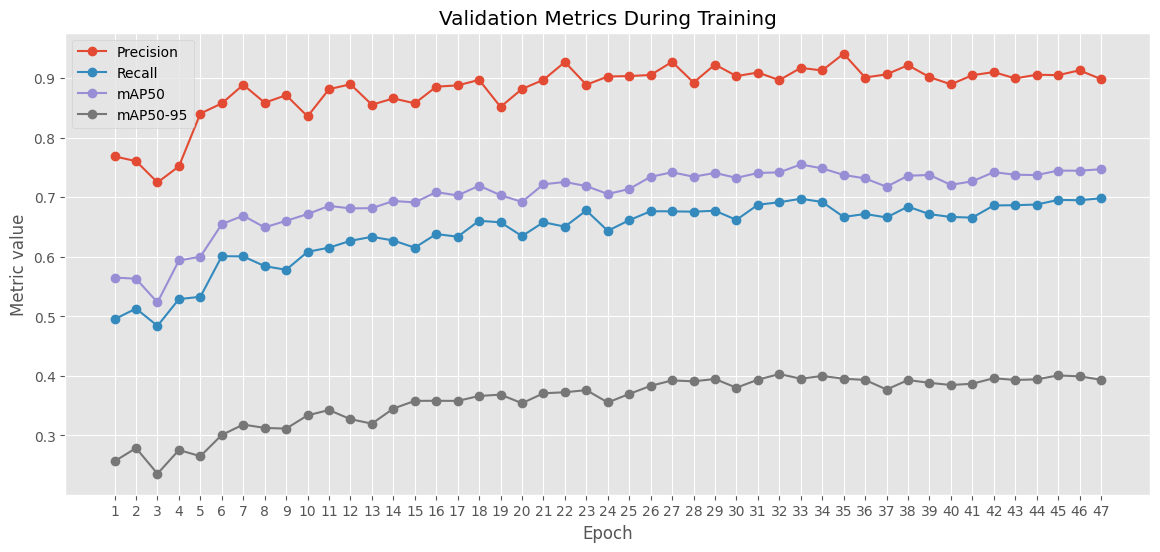

In [11]:
metrics = ['metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']

metrics_names = {
    'metrics/precision(B)': 'Precision',
    'metrics/recall(B)': 'Recall',
    'metrics/mAP50(B)': 'mAP50',
    'metrics/mAP50-95(B)': 'mAP50-95'
}

plt.figure(figsize=(14, 6))

for metric in metrics:
    plt.plot(results_df['epoch'], results_df[metric], label=metrics_names[metric], marker='o')

plt.xticks(range(1, results_df['epoch'].max()+1, 1))
plt.xlabel('Epoch')
plt.ylabel('Metric value')
plt.title('Validation Metrics During Training')
plt.legend()
plt.show()

Можна помітити, що приблизно після 30-ї епохи метрики на валідаційній вибірці майже перестали покращуватися. Вони продовжували трохи коливатися, але суттєвого зростання вже не було. Це означає, що модель вже навчилася знаходити птахів досить добре, а подальше навчання майже не покращувало результат.

## Зміна значень лосу на тренувальній та валідаційній вибірках

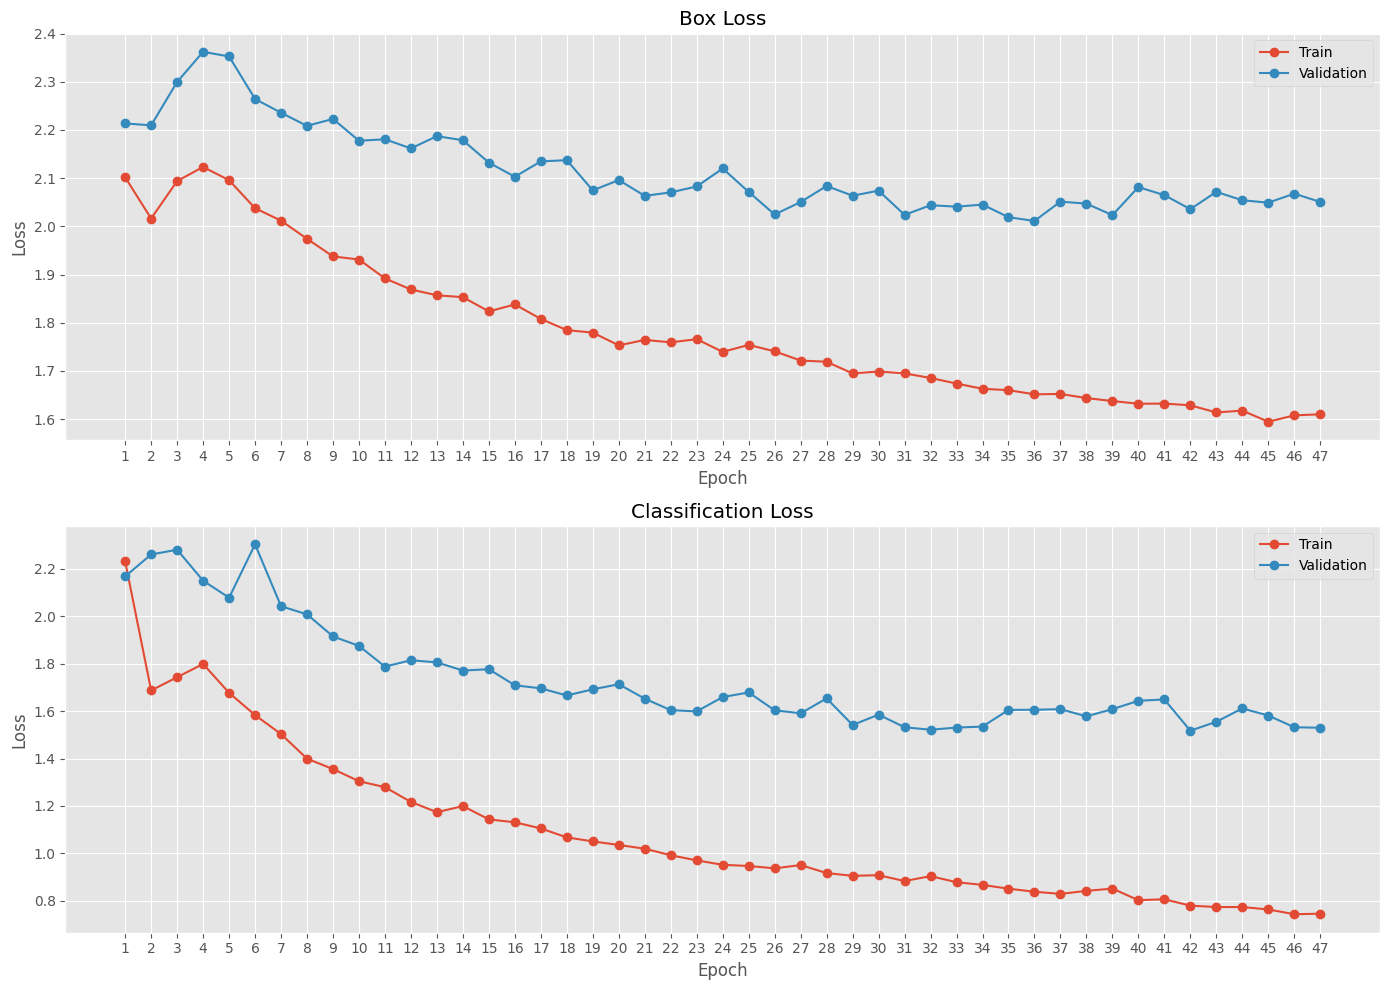

In [12]:
plt.figure(figsize=(14, 10))

# Box Loss
plt.subplot(2, 1, 1)
plt.plot(results_df["epoch"], results_df["train/box_loss"], label="Train", marker='o')
plt.plot(results_df["epoch"], results_df["val/box_loss"], label="Validation", marker='o')
plt.title("Box Loss")
plt.xticks(range(1, results_df['epoch'].max()+1, 1))
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


# Classification Loss
plt.subplot(2, 1, 2)
plt.plot(results_df["epoch"], results_df["train/cls_loss"], label="Train", marker='o')
plt.plot(results_df["epoch"], results_df["val/cls_loss"], label="Validation", marker='o')
plt.title("Classification Loss")
plt.xticks(range(1, results_df['epoch'].max()+1, 1))
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()


plt.tight_layout()
plt.show()

На графіках Box Loss та Classification Loss можна побачити схожу тенденцію з попередніми графіками метрик. Приблизно після 30-ї епохи значення Loss на валідаційній вибірці майже перестали зменшуватися, хоча на тренувальній вибірці вони продовжували знижуватися. Це означає, що модель продовжувала покращуватися на навчальних даних, але на нових зображеннях суттєвих покращень уже не було. Це може бути ознакою початку перенавчання (overfitting).

## Метрики найкращої епохи

In [6]:
results_df['fitness'] = ( 0.1 * results_df['metrics/mAP50(B)'] ) + ( 0.9 * results_df['metrics/mAP50-95(B)'] )

best_epoch = results_df['fitness'].idxmax()
best_results = results_df.loc[best_epoch]

summary = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'mAP50', 'mAP50-95'],
    'Value': [
        best_results.at['metrics/precision(B)'],
        best_results.at['metrics/recall(B)'],
        best_results.at['metrics/mAP50(B)'],
        best_results.at['metrics/mAP50-95(B)']
    ]
})

print(f'Best epoch: {int(best_results.at["epoch"])}')
print(summary)

Best epoch: 32
      Metric    Value
0  Precision  0.89698
1     Recall  0.69183
2      mAP50  0.74208
3   mAP50-95  0.40317


Найкращі результати модель показала на 32-й епосі навчання. Можна побачити, що метрика Precision становить приблизно 89.7%. Це означає, що серед усіх детекцій, які зробила модель, майже 90% були правильними. Тобто модель досить рідко помилково визначає інші об'єкти (в нашому випадку фон де немає птахів) як птахів.

З іншого боку, Recall становить приблизно 69.2%, що є помітно нижчим значенням. Це свідчить про те, що модель поки має певні труднощі з виявленням усіх птахів на зображеннях: частина птахів, які дійсно присутні на кадрах, залишається невиявленою.

Що стосується інших метрик, mAP50 становить приблизно 74.2%, що свідчить про досить непогану здатність моделі знаходити птахів і визначати їхні bounding boxes за умови IoU не менше 0.5. Водночас mAP50-95 становить приблизно 40.3%. Це помітно нижче значення пояснюється тим, що ця метрика оцінює якість детекції за десятьма різними порогами IoU - від 0.5 до 0.95. Таким чином, результати вказують на те, що моделі легше приблизно визначити розташування птаха, ніж точно окреслити його межі.

Усі ці метрики були розраховані на валідаційній вибірці. Для більш об'єктивної оцінки здатності моделі узагальнювати результати на нові дані варто додатково провести оцінювання на окремій тестовій вибірці, яка не використовувалася ні під час навчання, ні під час валідації.